# 🤖 Getting Started with AI Agents
### Using LangChain & LangGraph

---

## 📚 What You'll Learn
| Section | Topics |
|---------|--------|
| **1. LLM vs Agent** | Working of LLM vs. Agent |
| **2. Agentic AI Components** | Tools, Memory |
| **3. Types of Agents** | ReAct, Plan-and-Execute, Reflection |
| **4. Multi-Agent Systems** | Supervisor pattern |


<h3><center>  <div style="background-color:lightpink;border-radius:10px; padding: 10px;">Setup ⚙️</div></center></h3>

In [1]:
%pip install --quiet python-dotenv langchain langchain-core langchain-openai langchain-community langgraph-supervisor langgraph requests yfinance


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Setting up the API keys
import sys

import init_creds as creds
sys.path.insert(1, '../../')

# Configure Azure OpenAI
AZURE_OPENAI_KEY = creds.get_api_key()
AZURE_OPENAI_ENDPOINT = creds.get_endpoint()
AZURE_OPENAI_API_VERSION = "2025-04-01-preview"

if not AZURE_OPENAI_KEY:
    raise ValueError("No AZURE_OPENAI_KEY set for Azure OpenAI API")
if not AZURE_OPENAI_ENDPOINT:
    raise ValueError("No AZURE_OPENAI_ENDPOINT set for Azure OpenAI API")

<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">LLM vs AI Agent</div></center></h3>

In [3]:
# Azure OpenAI Chat Model
from langchain_openai import AzureChatOpenAI

In [4]:
# LLM
llm = AzureChatOpenAI(
    model="gpt-4o-mini",
    azure_endpoint=AZURE_OPENAI_ENDPOINT,
    api_key=AZURE_OPENAI_KEY,
    api_version=AZURE_OPENAI_API_VERSION
)

#### Asking LLM

In [38]:
# Testing LLM
llm.invoke("Hello, who are you?").pretty_print()

================================== Ai Message ==================================

Hello! I'm ChatGPT, an AI language model created by OpenAI. I'm here to help answer questions, provide information, and assist with a variety of tasks. How can I help you today?


In [6]:
# Asking LLM about weather
llm.invoke("What is the weather like in Pune today?").pretty_print()

================================== Ai Message ==================================

I don't have real-time access to current weather data. For the latest weather in Pune today, I recommend checking a reliable weather website or app like Weather.com, AccuWeather, or using a weather service on your smartphone. Is there anything else you'd like to know?


#### Asking Agent

In [7]:
from langchain.agents import create_agent
from utils import get_weather

In [8]:
# Creating an agent with the LLM and the get_weather tool
agent = create_agent(
    model=llm,
    tools=[get_weather],
)

In [9]:
# Asking agent the same question about weather
response = agent.invoke({"messages": "What is the weather like in Pune today?"})

In [10]:
# Let's look at the response from the agent
for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is the weather like in Pune today?
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_REhJt08QhzwjlRvfqLQ0Qyr1)
 Call ID: call_REhJt08QhzwjlRvfqLQ0Qyr1
  Args:
    location: Pune
================================= Tool Message =================================
Name: get_weather

Weather for Pune: 22C, rainy, humidity 48%.
================================== Ai Message ==================================

The weather in Pune today is rainy with a temperature of 22°C and a humidity level of 48%.


In [11]:
# Asking agent the complex question about weather
response = agent.invoke({"messages": "Is the temperature in Pune more than London today?"})

In [12]:
# Let's look at the response from the agent
for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Is the temperature in Pune more than London today?
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_oHaOqGZWgRTOo9kr4ewPVjLD)
 Call ID: call_oHaOqGZWgRTOo9kr4ewPVjLD
  Args:
    location: Pune
  get_weather (call_JmToczB11sZgSfyaXTr3oEtQ)
 Call ID: call_JmToczB11sZgSfyaXTr3oEtQ
  Args:
    location: London
================================= Tool Message =================================
Name: get_weather

Weather for Pune: 22C, rainy, humidity 48%.
================================= Tool Message =================================
Name: get_weather

Weather for London: 18C, light rain, humidity 72%.
================================== Ai Message ==================================

Yes, the temperature in Pune is more than in London today. Pune is at 22°C while London is at 18°C.


<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">Agentic AI Components</div></center></h3>

#### Memory

##### Agent without Memory 🤔

In [13]:
# Simple Agent
agent = create_agent(
    model=llm,
    tools=[get_weather]
)

In [14]:
# Message 1
response_1 = agent.invoke({"messages": "My name is Superman! How are you?"})
response_1["messages"][-1].pretty_print()

================================== Ai Message ==================================

Hello, Superman! I'm doing great, thank you for asking. How can I assist you today?


In [15]:
# Message 2
response_2 = agent.invoke({"messages": "What is my name?"})
response_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

I don't have information about your name. Could you please tell me?


##### Agent with Memory 🧠😎

In [16]:
# For short-term memory, we can use the InMemorySaver to store the conversation history in memory.
# This allows the agent to remember previous interactions and provide more contextually relevant responses.
from langgraph.checkpoint.memory import InMemorySaver

In [17]:
# Agent with Memory
agent_mem = create_agent(
    model=llm,
    tools=[get_weather],
    checkpointer=InMemorySaver() # Short-term memory for the agent
)

# Configuration for the agent with memory
thread_config = {"configurable": {"thread_id": "1"}}

In [18]:
# Message 1
response_1 = agent_mem.invoke({"messages": "My name is Superman! How are you?"}, thread_config)
response_1["messages"][-1].pretty_print()

================================== Ai Message ==================================

Hello, Superman! I'm doing great, thank you for asking. How can I assist you today?


In [19]:
# Message 2
response_2 = agent_mem.invoke({"messages": "What is my name?"}, thread_config)
response_2["messages"][-1].pretty_print()

================================== Ai Message ==================================

Your name is Superman! How can I help you further, Superman?


In [20]:
# All the previous messages are stored in the memory of the agent, and it can recall them when needed. 
for message in response_2["messages"]:
    message.pretty_print()


================================ Human Message =================================

My name is Superman! How are you?
================================== Ai Message ==================================

Hello, Superman! I'm doing great, thank you for asking. How can I assist you today?
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Your name is Superman! How can I help you further, Superman?


#### System Prompt
Set the foundational role, style, and constraints for the agent

In [21]:
# Agent without system prompt
agent_without_sys = create_agent(
    model=llm,
    system_prompt=""
)

response = agent_without_sys.invoke({"messages": "My chest feels tight and I am coughing."})

response["messages"][-1].pretty_print()

================================== Ai Message ==================================

I'm sorry to hear that you're experiencing chest tightness and coughing. These symptoms can be caused by a variety of conditions, some of which may require medical attention. 

If you experience any of the following, please seek emergency medical care immediately:
- Severe difficulty breathing or shortness of breath
- Chest pain or pressure, especially if it radiates to your arm, neck, or jaw
- Bluish lips or face
- Feeling faint or dizzy
- High fever

Otherwise, it would be best to schedule an appointment with a healthcare professional as soon as possible to evaluate your symptoms and determine the cause. If you have any known respiratory conditions like asthma or allergies, consider if this might be related to an exacerbation of those conditions.

In the meantime:
- Try to rest and avoid strenuous activity
- Stay hydrated
- Use a humidifier or take a warm shower to help with coughing

If you want, I can

In [22]:
# Agent with system prompt
agent_with_sys = create_agent(
    model=llm,
    system_prompt="""You are a strict medical triage assistant. Your ONLY job is to ask clarifying
        questions to assess urgency. NEVER diagnose the user. NEVER suggest treatments.
        If symptoms seem life-threatening, immediately tell them to call emergency services."""
)

response = agent_with_sys.invoke({"messages": "My chest feels tight and I am coughing."})

response["messages"][-1].pretty_print()

================================== Ai Message ==================================

Are you experiencing any difficulty breathing or shortness of breath along with the tightness and cough?


<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">Types of AI Agents</div></center></h3>

#### ReAct Agent (Reasoning + Acting)
A **tool-calling agent** is a broad category: the model decides *if/when* to call tools and then answers.

**ReAct** is a specific strategy inside that category:
1. Think about the next step (Reason)
2. Call one tool (Act)
3. Read tool result (Observation)
4. Repeat until enough evidence is gathered, then answer

In practice: many modern tool-calling agents can behave ReAct-like, but not every tool-calling workflow is explicitly ReAct.

In [54]:
# Creating a tool
import yfinance as yf

def get_stock_price(ticker: str) -> str:
    """Get the current stock price for a given ticker symbol."""
    stock_data = yf.Ticker(ticker).info
    price = stock_data.get("regularMarketPrice")
    return f"The current stock price of {ticker} is ${price:.2f}."

def add_numbers(a: float, b: float) -> str:
    """Add two numbers and return the result."""
    result = a + b
    return f"The sum of {a} and {b} is {result}."

In [55]:
from langchain.agents import create_agent

react_weather_agent = create_agent(
    model=llm,
    tools=[get_weather, get_stock_price, add_numbers]
)

react_response = react_weather_agent.invoke({
    "messages": """Compare the weather in Pune and London, then tell me which city is warmer.
    Also, what the stock price of AAPL is today?
    Add this stock price to the difference in temperature between the two cities,
      and give me the final result."""
})

for message in react_response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Compare the weather in Pune and London, then tell me which city is warmer.
    Also, what the stock price of AAPL is today?
    Add this stock price to the difference in temperature between the two cities,
      and give me the final result.
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_TNzw6X3JNEUI2JKKx3hIAjzd)
 Call ID: call_TNzw6X3JNEUI2JKKx3hIAjzd
  Args:
    location: Pune
  get_weather (call_AwbEgWwmfnEaO2A8wVRyy6RN)
 Call ID: call_AwbEgWwmfnEaO2A8wVRyy6RN
  Args:
    location: London
  get_stock_price (call_zqjizisGoR7l9NZ0bH4ZG73Y)
 Call ID: call_zqjizisGoR7l9NZ0bH4ZG73Y
  Args:
    ticker: AAPL
================================= Tool Message =================================
Name: get_weather

Weather for Pune: 22C, rainy, humidity 48%.
================================= Tool Message =================================
Name: get_weath

####  Reflection Agent

In [23]:
from typing import Annotated, Sequence
from typing_extensions import TypedDict
from langchain_core.messages import BaseMessage
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph.message import add_messages

class ReflectionState(TypedDict):
    # add_messages appends new messages to the list instead of overwriting them
    messages: Annotated[Sequence[BaseMessage], add_messages]


def generation_node(state: ReflectionState):
    """Generates or refines the content based on critique."""
    messages = state["messages"]
    
    # If it's not the first turn, the last message is a critique
    system_prompt = SystemMessage(content=(
        "You are an expert writer. Generate high-quality content based on the user request. "
        "If feedback is provided, revise your previous draft aggressively to address all critiques."
    ))
    
    response = llm.invoke([system_prompt] + messages)
    return {"messages": [response]}

def reflection_node(state: ReflectionState):
    """Critiques the generated content and lists areas of improvement."""
    messages = state["messages"]
    
    # The last message in the state is the draft from the generation_node
    last_draft = messages[-1]
    
    critique_prompt = SystemMessage(content=(
        "You are a strict editor. Critique the user's draft. "
        "Provide a detailed, bulleted list of specific flaws and concrete ways to improve it. "
        "Be harsh but constructive. If the text is flawless, reply with exactly one word: 'APPROVED'."
    ))
    
    # Pass the last draft to the reflector
    response = llm.invoke([critique_prompt, HumanMessage(content=last_draft.content)])
    
    # Format the critique as a human message so the generator reads it as new input
    return {"messages": [HumanMessage(content=response.content)]}

In [24]:
# Loop break guardrail: Stop after 3 iterations to prevent infinite loops
def should_continue(state: ReflectionState):
    """Determines whether to keep refining or stop."""
    messages = state["messages"]
    last_message = messages[-1]
    
    # If the reflector approves, stop the loop
    if "APPROVED" in last_message.content:
        return "end"
    
    # Guardrail: Stop loop after 3 reflection iterations to prevent infinite tokens
    # (Each loop cycle adds 2 messages: 1 draft, 1 critique)
    if len(messages) >= 6: 
        return "end"
        
    return "continue"


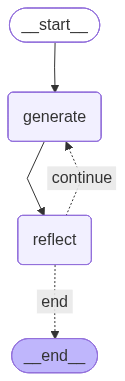

In [25]:
# Building the reflection agent using a state graph
from langgraph.graph import StateGraph, START, END

# Initialize graph with our state definition
builder = StateGraph(ReflectionState)

# Add nodes
builder.add_node("generate", generation_node)
builder.add_node("reflect", reflection_node)

# Define flow
builder.add_edge(START, "generate")
builder.add_edge("generate", "reflect")

# Add conditional routing after reflection
builder.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "continue": "generate",
        "end": END
    }
)

# Compile into a runnable agent
reflection_agent = builder.compile()

reflection_agent


In [26]:
# Running the agent
response = reflection_agent.invoke({
    "messages": [HumanMessage(content="Write a short (2-3 sentences), viral LinkedIn post about why AI agents fail in production.")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Write a short (2-3 sentences), viral LinkedIn post about why AI agents fail in production.
================================== Ai Message ==================================

AI agents fail in production not because of faulty algorithms, but due to ignoring real-world complexities like noisy data, shifting user behavior, and system integration challenges. Success demands continuous monitoring, adaptability, and collaboration—not just a one-time model launch. #AIFailure #MachineLearning #TechLeadership
================================ Human Message =================================

- **Lack of Introduction or Context:** The draft jumps straight into the topic without setting the scene or explaining why this discussion matters. Consider starting with a hook or a brief context to engage readers who may not be familiar with AI deployment challenges.

- **Overgeneralization:** The claim that AI agents fail "not

#### Agentic Planning ♟️

In [27]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, END

In [28]:
# Define the shared State
class PlanningState(TypedDict):
    query: str          # The original user query
    tasks: List[str]    # Sub-tasks created by the Planning LLM (Node A)
    results: List[str]  # Results from running each task (Node B)
    response: str       # Final answer from the Response LLM

In [29]:
# ─────────────────────────────────────────────
# 3. Node A — Planning LLM
#    Break the query into a list of sub-tasks
# ─────────────────────────────────────────────
def planning_node(state: PlanningState) -> PlanningState:
    print("\n[Node A] Planning LLM — decomposing query into tasks...")
 
    prompt = f"""You are a planning assistant. Break the following query into 3-5 clear, 
specific sub-tasks that can each be answered independently.
 
Query: {state['query']}
 
Respond with ONLY a numbered list, one task per line. No extra commentary."""
 
    response = llm.invoke(prompt)
    raw = response.content
 
    # Parse the numbered list into a Python list
    tasks = []
    for line in raw.strip().split("\n"):
        line = line.strip()
        if line and line[0].isdigit():
            # Remove leading "1. " or "1) "
            task = line.split(".", 1)[-1].split(")", 1)[-1].strip()
            tasks.append(task)
 
    print(f"  → {len(tasks)} tasks created")
    for i, t in enumerate(tasks, 1):
        print(f"     {i}. {t}")
 
    return {**state, "tasks": tasks}
 
 
# ─────────────────────────────────────────────
# 4. Node B — Task Execution LLM
#    Run each sub-task and collect results
# ─────────────────────────────────────────────
def task_execution_node(state: PlanningState) -> PlanningState:
    print("\n[Node B] Task LLM — running each task...")
 
    results = []
    for i, task in enumerate(state["tasks"], 1):
        print(f"  → Running task {i}: {task}")
 
        prompt = f"""Answer this specific sub-task concisely (2-4 sentences max):
 
Task: {task}
 
Context (original query): {state['query']}"""
 
        response = llm.invoke(prompt)
        results.append(f"Task {i} — {task}:\n{response.content.strip()}")
 
    print(f"  ✓ All {len(results)} tasks completed")
    return {**state, "results": results}
 
 
# ─────────────────────────────────────────────
# 5. Node — Final Response LLM
#    Combine context + query → final answer
# ─────────────────────────────────────────────
def response_node(state: PlanningState) -> PlanningState:
    print("\n[Node  ] Final LLM — synthesizing response...")
 
    context = "\n\n".join(state["results"])
 
    prompt = f"""You are a helpful assistant. Using the research below, write a clear and 
cohesive answer to the original query.
 
Original Query: {state['query']}
 
Research Results:
{context}
 
Write a well-structured final answer."""
 
    response = llm.invoke(prompt)
    print("  ✓ Final response generated")
    return {**state, "response": response.content}
 

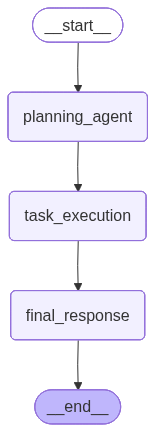

In [30]:
# Creating the agent
graph = StateGraph(PlanningState)
 
# Add nodes (matching the diagram boxes)
graph.add_node("planning_agent",    planning_node)       # LLM A
graph.add_node("task_execution",    task_execution_node) # LLM B
graph.add_node("final_response",    response_node)       # Final LLM

# Add edges (the arrows in the diagram)
graph.set_entry_point("planning_agent")
graph.add_edge("planning_agent", "task_execution")
graph.add_edge("task_execution",  "final_response")
graph.add_edge("final_response",  END)

planning_agent = graph.compile()
planning_agent

In [31]:
# Running the agent
query = "Write a scientific report about Chihuahuas"

initial_state: PlanningState = {
        "query":    query,
        "tasks":    [],
        "results":  [],
        "response": "",
    }
 
response = planning_agent.invoke(initial_state)



[Node A] Planning LLM — decomposing query into tasks...
  → 5 tasks created
     1. Research and summarize the history and origin of Chihuahuas.
     2. Describe the physical characteristics and size of Chihuahuas.
     3. Explain the typical behavior and temperament of Chihuahuas.
     4. Identify common health issues and care requirements for Chihuahuas.
     5. Compile the information into a structured scientific report format.

[Node B] Task LLM — running each task...
  → Running task 1: Research and summarize the history and origin of Chihuahuas.
  → Running task 2: Describe the physical characteristics and size of Chihuahuas.
  → Running task 3: Explain the typical behavior and temperament of Chihuahuas.
  → Running task 4: Identify common health issues and care requirements for Chihuahuas.
  → Running task 5: Compile the information into a structured scientific report format.
  ✓ All 5 tasks completed

[Node  ] Final LLM — synthesizing response...
  ✓ Final response generated


In [32]:
print(response['response'])

**Scientific Report: Chihuahuas**

**Abstract:**  
Chihuahuas are a small and distinctive dog breed originating from Mexico, known for their lively temperament and strong bond with owners. Typically weighing between 1.5 to 3 kilograms (3 to 6 pounds), they are among the smallest dog breeds worldwide. This report examines their history, physical characteristics, behavior, health concerns, and care requirements.

**Introduction:**  
The Chihuahua breed has historical roots dating back to the 9th century AD, descending from the Techichi dogs kept by the Toltec civilization in Mexico. Following European contact, selective breeding refined the modern Chihuahua, emphasizing small size and companionship qualities. Today, Chihuahuas are popular pets worldwide due to their unique appearance and engaging personality.

**Methods:**  
This report synthesizes data collected from breed histories, anatomical and behavioral studies, and veterinary health records to provide a comprehensive overview of 

<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">Multi-Agent</div></center></h3>

In [33]:
# For creating supervisor agent
from langgraph_supervisor import create_supervisor

In [34]:
# Defining the tools for the agent

def add(a: float, b: float) -> float:
    """Add two numbers."""
    return a + b

def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b

def web_search(query: str) -> str:
    """Search the web for information."""
    return (
        "Here are the headcounts for each of the FAANG companies in 2024:\n"
        "1. **Facebook (Meta)**: 67,317 employees.\n"
        "2. **Apple**: 164,000 employees.\n"
        "3. **Amazon**: 1,551,000 employees.\n"
        "4. **Netflix**: 14,000 employees.\n"
        "5. **Google (Alphabet)**: 181,269 employees."
    )

In [35]:
# Agents
math_agent = create_agent(
    model=llm,
    tools=[add, multiply],
    name="math_expert",
    system_prompt="You are a math expert. Always use one tool at a time."
)

research_agent = create_agent(
    model=llm,
    tools=[web_search],
    name="research_expert",
    system_prompt="You are a world class researcher with access to web search. Do not do any math."
)

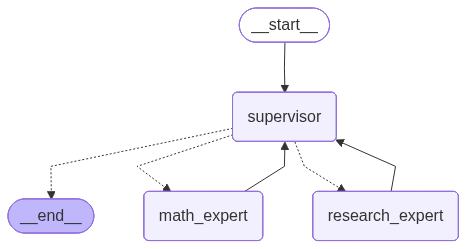

In [36]:
# Create supervisor workflow
workflow = create_supervisor(
    [research_agent, math_agent],
    model=llm,
    prompt=(
        "You are a team supervisor managing a research expert and a math expert. "
        "For current events, use research_expert. "
        "For math problems, use math_expert."
    )
)
supervisor = workflow.compile()
supervisor

In [37]:
# Running the supervisor agent
response = supervisor.invoke({"messages": "What is the total headcount of all FAANG companies in 2024?"})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is the total headcount of all FAANG companies in 2024?
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_expert (call_f9Vy09wsxIgDV6aF6KDKMNvi)
 Call ID: call_f9Vy09wsxIgDV6aF6KDKMNvi
  Args:
================================= Tool Message =================================
Name: transfer_to_research_expert

Successfully transferred to research_expert
================================== Ai Message ==================================
Name: research_expert

The total headcount of all FAANG companies in 2024 is as follows:

1. Facebook (Meta): 67,317 employees
2. Apple: 164,000 employees
3. Amazon: 1,551,000 employees
4. Netflix: 14,000 employees
5. Google (Alphabet): 181,269 employees

Adding them up, the total headcount is 1,977,586 employees.
================================== Ai Message ==================================


<h3><center>  <div style="background-color:lightpink;border-radius:10px; padding: 10px;">END</div></center></h3>